# How `planeFit` works

`planeFit` is a small helper in [main.ipynb](../main.ipynb). You give it a cloud of points and it returns the flat plane that fits them best, as two things:

- **p**, a point on the plane (the centroid, i.e. the average of the points)
- **n**, the plane's normal: a unit vector perpendicular to the plane

S4 Slicer uses it to work out **which way each overhanging tetrahedron should tilt** (section 6).

This notebook:
1. Shows the function as it appears in the slicer.
2. Runs it one line at a time on a small example.
3. Explains why the last singular vector is the normal.
4. Plots the result.
5. Lists the edge cases to watch for.
6. Shows how the slicer uses the normal.

In [17]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)

## 1. The function

Copied unchanged from `main.ipynb`.

In [18]:
def planeFit(points):
    """
    p, n = planeFit(points)

    Given an array, points, of shape (d,...)
    representing points in d-dimensional space,
    fit an d-dimensional plane to the points.
    Return a point, p, on the plane (the point-cloud centroid),
    and the normal, n.
    """
    import numpy as np
    from numpy.linalg import svd
    points = np.reshape(points, (np.shape(points)[0], -1))
    assert points.shape[0] <= points.shape[1], "There are only {} points in {} dimensions.".format(points.shape[1], points.shape[0])
    ctr = points.mean(axis=1)
    x = points - ctr[:,np.newaxis]
    M = np.dot(x, x.T)
    return ctr, svd(M)[0][:,-1]

## 2. Example points

To check the answer we need points near a plane we already know. These are scattered around $z = 0.3x - 0.5y + 2$, with a little noise added.

**Shape convention:** `planeFit` expects shape `(d, N)`: one *row* per coordinate (x, y, z) and one *column* per point. Most code, the slicer included, stores one point per row, `(N, d)`, so you pass `points.T`.

In [19]:
rng = np.random.default_rng(42)
N = 30
x = rng.uniform(-5, 5, N)
y = rng.uniform(-5, 5, N)
z = 0.3 * x - 0.5 * y + 2 + rng.normal(0, 0.2, N)

pts_rows = np.column_stack([x, y, z])   # (N, 3): one point per row
pts = pts_rows.T                        # (3, N): the layout planeFit wants
print("one point per row:", pts_rows.shape, "  planeFit layout:", pts.shape)

# exact normal of 0.3x - 0.5y - z + 2 = 0, scaled to length 1
true_n = np.array([0.3, -0.5, -1.0])
true_n /= np.linalg.norm(true_n)
print("true normal:", true_n)

one point per row: (30, 3)   planeFit layout: (3, 30)
true normal: [ 0.2592 -0.4319 -0.8639]


## 3. Line by line

### Step 1: reshape

```python
points = np.reshape(points, (np.shape(points)[0], -1))
```

This keeps the first axis (the d coordinates) and flattens everything after it into one list of points. A plain `(3, N)` array comes out unchanged. It matters if you pass something like a `(3, H, W)` grid of points, which becomes `(3, H*W)`.

In [20]:
P = np.reshape(pts, (np.shape(pts)[0], -1))
print(P.shape)

grid = np.zeros((3, 4, 5))   # e.g. a 4 x 5 grid of 3D points
print(grid.shape, "->", np.reshape(grid, (3, -1)).shape)

(3, 30)
(3, 4, 5) -> (3, 20)


### Step 2: the assert

```python
assert points.shape[0] <= points.shape[1], ...
```

This reads as "at least as many points as dimensions". In 3D you need at least 3 points to pin down a plane.

It also catches the most common mistake, passing `(N, 3)` instead of `(3, N)`. With more than 3 points the assert fails, and the odd-looking message is the hint to transpose:

In [21]:
try:
    planeFit(pts_rows)        # wrong layout: (30, 3)
except AssertionError as e:
    print("AssertionError:", e)

AssertionError: There are only 3 points in 30 dimensions.


### Step 3: the centroid

```python
ctr = points.mean(axis=1)
```

The average of all the points, one value per coordinate. The best-fit plane always passes through the centroid. Whichever way the plane faces, sliding it so it goes through the average point is what minimises the squared distances. That's why the centroid is the point the function returns.

In [22]:
ctr = P.mean(axis=1)
print("centroid:", ctr)

centroid: [ 0.5914 -0.1952  2.2492]


### Step 4: centre the points

```python
x = points - ctr[:,np.newaxis]
```

Subtract the centroid from every point so the cloud sits around the origin. `ctr[:, np.newaxis]` turns the shape-`(3,)` vector into a `(3, 1)` column, so NumPy subtracts it from all N columns at once.

In [23]:
X = P - ctr[:, np.newaxis]
print(X.shape, "  mean after centring:", X.mean(axis=1))

(3, 30)   mean after centring: [-0. -0. -0.]


### Step 5: the scatter matrix

```python
M = np.dot(x, x.T)
```

`M` is 3 × 3 (d × d in general) however many points there are. It equals N times the covariance matrix.

- **Diagonal:** how spread out the points are along x, along y and along z.
- **Off-diagonal:** how two coordinates move together. Here z falls as y rises, so `M[1, 2]` is negative.

The key property: for any unit vector $n$, the quantity $n^T M n$ equals **the sum of squared distances from the points to the plane through the centroid with normal $n$**. Each centred point's distance to that plane is $n \cdot x_i$, and

$$\sum_i (n \cdot x_i)^2 = n^T \Big(\sum_i x_i x_i^T\Big) n = n^T M n.$$

So finding the best plane comes down to finding the unit vector $n$ that makes $n^T M n$ as small as possible.

This is *perpendicular* distance, so x, y and z are all treated alike. Ordinary regression, $z = ax + by + c$, only measures error in the vertical direction.

In [24]:
M = np.dot(X, X.T)
print(M)
print("\nequals N * covariance:", np.allclose(M, N * np.cov(P, bias=True)))

# n @ M @ n really is the sum of squared distances to the plane
n_try = np.array([0.0, 0.0, 1.0])   # a horizontal plane: deliberately wrong
print("\nvia M:   ", n_try @ M @ n_try)
print("directly:", np.sum((n_try @ X) ** 2))

[[ 253.9177   14.3691   66.9152]
 [  14.3691  211.4139 -102.4181]
 [  66.9152 -102.4181   71.762 ]]

equals N * covariance: True

via M:    71.76198413647764
directly: 71.76198413647765


### Step 6: the SVD

```python
return ctr, svd(M)[0][:,-1]
```

`svd(M)` returns `U, S, Vt`. `M` is symmetric and never negative in any direction, so its SVD is the same as its eigendecomposition:

- The columns of `U` are three perpendicular directions, the principal axes of the point cloud.
- `S` holds how much spread there is along each one, **sorted largest first**.

The direction that makes $n^T M n$ smallest is the one with the smallest value in `S`, which is the **last** column of `U`. That's what `svd(M)[0][:, -1]` picks out. The first two columns lie in the plane, along the directions the points spread out; the last one points straight out of it.

(`np.linalg.eigh(M)` gives the same vector as its *first* column, because `eigh` sorts smallest first.)

In [25]:
from numpy.linalg import svd

U, S, Vt = svd(M)
print("singular values S:", S, " <- two large (in-plane spread), one small (off-plane)")
print("U =\n", U)

n = U[:, -1]
print("\nfitted normal:", n)
print("true normal:  ", true_n)
print("angle between them: %.2f degrees" % np.degrees(np.arccos(abs(n @ true_n))))

singular values S: [286.5013 250.1676   0.4247]  <- two large (in-plane spread), one small (off-plane)
U =
 [[-0.7363 -0.6277 -0.2527]
 [ 0.4923 -0.7531  0.4364]
 [-0.4642  0.1969  0.8635]]

fitted normal: [-0.2527  0.4364  0.8635]
true normal:   [ 0.2592 -0.4319 -0.8639]
angle between them: 0.45 degrees


Every sign of the fitted normal is the opposite of the true one. Both are correct normals of the same plane, one pointing up and one pointing down (section 5a covers this). That's why the angle check uses `abs`.

The smallest singular value *is* the minimum sum of squared distances. Any other direction does worse:

In [26]:
print("fitted normal:      n M n = %.3f  (smallest singular value = %.3f)" % (n @ M @ n, S[-1]))
for v in rng.normal(size=(3, 3)):
    v /= np.linalg.norm(v)
    print("random direction:   n M n = %.3f" % (v @ M @ v))

fitted normal:      n M n = 0.425  (smallest singular value = 0.425)
random direction:   n M n = 138.254
random direction:   n M n = 185.094
random direction:   n M n = 189.514


### Same answer from the function

In [27]:
p, n = planeFit(pts)
print("p =", p)
print("n =", n)

p = [ 0.5914 -0.1952  2.2492]
n = [-0.2527  0.4364  0.8635]


## 4. Picture

The points are blue, the fitted plane is green and the normal is the orange arrow. The plane is drawn using the first two columns of `U`, the in-plane directions.

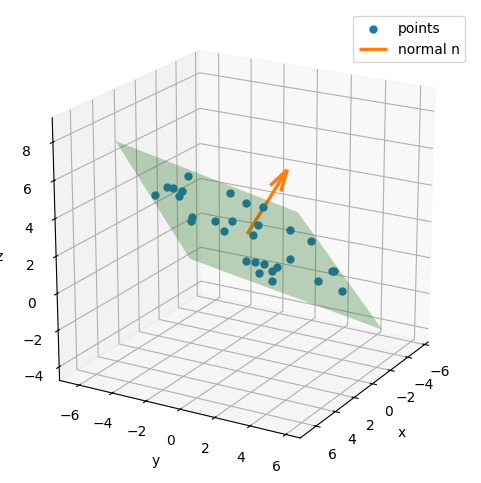

In [28]:
u1, u2 = U[:, 0], U[:, 1]
s, t = np.meshgrid(np.linspace(-6, 6, 2), np.linspace(-6, 6, 2))
plane = p[:, None, None] + u1[:, None, None] * s + u2[:, None, None] * t

fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(projection="3d")
ax.scatter(*pts, color="tab:blue", s=25, depthshade=False, label="points")
ax.plot_surface(*plane, color="tab:green", alpha=0.3)
ax.quiver(*p, *(4 * n), color="tab:orange", linewidth=2.5, label="normal n")

# same scale on every axis, otherwise the normal won't look perpendicular
r = 7
ax.set_xlim(p[0] - r, p[0] + r); ax.set_ylim(p[1] - r, p[1] + r); ax.set_zlim(p[2] - r, p[2] + r)
ax.set_box_aspect((1, 1, 1))
ax.view_init(elev=20, azim=30)   # the default camera sees this plane edge-on
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z")
ax.legend()
plt.show()

## 5. Things to watch out for

### 5a. The sign of the normal is arbitrary

Every plane has two normals, $n$ and $-n$, and either is a correct answer. SVD doesn't promise which one you get. That matters for the slicer, because it reads the **sign** of `n[:2]` (see section 6).

The test below fits 5,000 random sloped patches and counts how often the normal points up ($n_z > 0$) and how often it points down.

In [29]:
up = down = 0
for _ in range(5000):
    a, b = rng.uniform(-5, 5, size=2)                     # random slope
    xy = rng.uniform(-1, 1, size=(6, 2)) + rng.uniform(-20, 20, size=2)
    zz = a * xy[:, 0] + b * xy[:, 1] + rng.normal(0, 0.01, 6)
    _, nn = planeFit(np.column_stack([xy, zz]).T)
    if nn[2] > 0:
        up += 1
    else:
        down += 1
print("normal points up:", up, "  normal points down:", down)

normal points up: 4953   normal points down: 47


Most fits come back pointing up, but not all. If the direction matters, flip it yourself after the fit:

```python
p, n = planeFit(points)
if n[2] < 0:
    n = -n
```

### 5b. Points that don't define a plane

If all the points lie on one line, infinitely many planes contain them. The singular values show it: **two** are near zero instead of one, so the "last column" is an arbitrary choice between two directions. A quick check is whether the second-smallest singular value is also close to zero.

In [30]:
tt = np.linspace(0, 1, 10)
line = np.vstack([tt, 2 * tt, 3 * tt])        # every point on one line
Xl = line - line.mean(axis=1)[:, None]
print("singular values:", svd(Xl @ Xl.T)[1])

singular values: [14.2593  0.      0.    ]


The slicer skips cells with fewer than 3 points, but it doesn't check for this case.

### 5c. Exactly d points in the wrong layout

With more than 3 points the assert catches a `(N, 3)` array. With **exactly** 3 points the array is `(3, 3)` either way, so the assert passes and a missing `.T` silently gives a wrong normal:

In [31]:
three = pts_rows[:3]                      # 3 points, one per row
print("with .T (correct):", planeFit(three.T)[1])
print("forgot .T:        ", planeFit(three)[1])

with .T (correct): [-0.1804  0.426   0.8866]
forgot .T:         [0.1649 0.7046 0.6901]


## 6. How S4 Slicer uses it

Inside `calculate_path_length_to_base_gradient` in `main.ipynb`:

1. Dijkstra over the cell-neighbour graph gives every overhanging cell its **path length**: the distance to the nearest bottom cell, travelling cell centre to cell centre through the mesh.
2. For each overhanging cell, take it and its edge neighbours, and make one 3D point per cell: **(x, y of the cell centre, path length)**. Path length is used as a height, so the points form a small "path-length surface" over the xy plane. Because path length is a distance, all three coordinates are in the same units, which suits a perpendicular-distance fit.
3. Fit a plane to those points. Its tilt shows which way the path length increases.
4. Take the xy part of the normal and dot it with the unit vector pointing from the z-axis out to the cell (the **radial direction**). The result is a single number between −1 and 1 that says whether to tilt the cell inwards or outwards, and how strongly.

That number is stored as `path_length_to_base_gradient` and multiplied into the initial rotation field. The code that does it:

```python
points = np.hstack((tet.cell_data["cell_center"][local_cells, :2], local_cell_path_lengths[:, None]))
_, plane_normal = planeFit(points.T)

cell_center_direction_normalized = tet.cell_data["cell_center"][cell_index, :2] / np.linalg.norm(tet.cell_data["cell_center"][cell_index, :2])
gradient_in_radial_direction = np.dot(cell_center_direction_normalized, plane_normal[:2])
```

### From normal to slope

If the fitted plane is $z = ax + by + c$, its upward normal is

$$n = \frac{(-a,\ -b,\ 1)}{\sqrt{a^2 + b^2 + 1}}$$

so:

- The slope can be read back as $(a, b) = -n_{xy} / n_z$.
- With an upward normal, $n_{xy}$ points **downhill**, towards shorter path lengths. Its length is always below 1, so the result stays between −1 and 1 even on very steep slopes.

So with an upward normal, a **negative** value means the path to the base gets longer moving outward, and a **positive** value means it gets longer moving inward. If the fit returns the downward normal (5a), that sign flips. `main.ipynb` doesn't flip the normal to a fixed direction, so a small share of cells get the opposite sign. The smoothing and optimisation steps after it may hide this, but it's worth knowing.

### A made-up example

One overhanging cell at (10, 0) with six neighbours around it. Path length grows by 0.8 for every unit you move away from the z-axis.

In [32]:
cell = np.array([10.0, 0.0])
local_xy = np.vstack([cell, cell + rng.uniform(-1, 1, size=(6, 2))])
radius = np.linalg.norm(local_xy, axis=1)
path_length = 5 + 0.8 * (radius - 10)

points = np.hstack((local_xy, path_length[:, None]))    # (7, 3), one point per row, like the slicer
_, plane_normal = planeFit(points.T)

radial = cell / np.linalg.norm(cell)
gradient_in_radial_direction = np.dot(radial, plane_normal[:2])

print("plane_normal:", plane_normal)
print("slope from normal, -n_xy / n_z:", -plane_normal[:2] / plane_normal[2], " (expected about [0.8, 0])")
print("gradient_in_radial_direction: %.4f" % gradient_in_radial_direction)
print("expected with an upward normal: -0.8 / sqrt(1 + 0.8^2) = %.4f" % (-0.8 / np.sqrt(1 + 0.8**2)))

plane_normal: [-0.6229  0.0033  0.7823]
slope from normal, -n_xy / n_z: [ 0.7963 -0.0042]  (expected about [0.8, 0])
gradient_in_radial_direction: -0.6229
expected with an upward normal: -0.8 / sqrt(1 + 0.8^2) = -0.6247


The path to the base gets longer moving outward, so with an upward normal the value is negative. The slicer turns that sign into a tilt direction for this cell.

## 7. Putting it all together

The animation below runs the whole process on one slicer-style patch: an overhanging cell (red circle) and 11 neighbours, coloured by path length. The steps are:

1. **Build the points.** Each cell becomes (x, y, path length).
2. **Find the centroid.** This is the point `planeFit` returns.
3. **Centre the cloud** on the origin, so only the plane's direction is left to find.
4. **Find the normal.** The animation tries plane directions one by one and graphs how badly each fits. SVD jumps straight to the minimum without searching.
5. **Put the plane back** at the centroid.
6. **Use it.** Dot the normal's x/y part with the outward direction to get the cell's tilt value.

Jupyter can play animations. Matplotlib draws every frame and `to_jshtml()` packs them into a player with play/pause, step and a scrubber, so you can stop on any step. Rendering takes about 20 seconds. The output is about 6 MB; use **Clear All Outputs** before committing if you want to keep the file small.

The first cell sets up the data. The second only draws it, so you don't need to read it to follow along.

In [33]:
from numpy.linalg import svd

# An overhanging cell at (7, 5) and 11 neighbours around it, like one patch in the slicer.
# Path length grows by about 0.8 for every unit you move away from the z-axis.
rng_anim = np.random.default_rng(7)
cell_xy = np.array([7.0, 5.0])
cells_xy = np.vstack([cell_xy, cell_xy + rng_anim.uniform(-2.5, 2.5, size=(11, 2))])   # row 0 is the overhanging cell
path_len = 4 + 0.8 * (np.linalg.norm(cells_xy, axis=1) - np.linalg.norm(cell_xy)) + rng_anim.normal(0, 0.15, len(cells_xy))
cloud = np.column_stack([cells_xy, path_len])        # (N, 3): x, y, path length

# the planeFit steps
cloud_ctr, best_n = planeFit(cloud.T)
if best_n[2] < 0:     # point it up so the picture is consistent (see 5a)
    best_n = -best_n
cloud_centred = cloud - cloud_ctr
U_cloud = svd(cloud_centred.T @ cloud_centred)[0]
spread_dir, middle_dir = U_cloud[:, 0], U_cloud[:, 1]   # the two in-plane directions

# the slicer's use of it
radial = cell_xy / np.linalg.norm(cell_xy)
radial_value = radial @ best_n[:2]
print("normal:", best_n, "  outward . n_xy = %.3f" % radial_value)

normal: [-0.5064 -0.3722  0.7778]   outward . n_xy = -0.628


In [ ]:

from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# Each phase: (name, frames spent moving, frames held still at the end)
phases = [("lift", 12, 6), ("centroid", 6, 6), ("centre", 12, 6),
          ("sweep", 24, 0), ("settle", 8, 10), ("back", 10, 6), ("apply", 20, 14)]

timeline = []   # one (phase, t) per frame; t runs 0 -> 1 while moving, then stays at 1
for name, moving, held in phases:
    timeline += [(name, i / (moving - 1)) for i in range(moving)]
    timeline += [(name, 1.0)] * held

titles = {
    "lift":     ("Step 1 · Build the points",
                 "Each cell becomes a point: (x, y of its centre, path length to the base)."),
    "centroid": ("Step 2 · Find the centroid",
                 "The average point (black X). The best-fit plane always passes through it."),
    "centre":   ("Step 3 · Centre the cloud",
                 "Shift everything so the centroid sits on the origin. Now only the plane's direction is unknown."),
    "sweep":    ("Step 4 · Find the normal",
                 "Try different plane directions. Red lines are each point's distance to the plane;\n"
                 "the best normal makes the sum of their squares as small as possible."),
    "settle":   ("Step 4 · Find the normal",
                 "SVD finds this minimum directly: it's the last column of U."),
    "back":     ("Step 5 · Put the plane back",
                 "Shift back to the centroid. planeFit returns this point and the normal (orange)."),
    "apply":    ("Step 6 · How the slicer uses it",
                 "Dot the normal's x/y part with the outward direction. Negative: the path to the base gets longer moving\n"
                 "outward. The value is multiplied into the rotation field, so its sign sets which way the cell tilts."),
}

def smooth(t):
    return t * t * (3 - 2 * t)

def trial_normal(theta):
    return np.cos(theta) * best_n + np.sin(theta) * spread_dir

thetas = np.radians(np.linspace(-70, 70, 141))
ssd = [np.sum((cloud_centred @ trial_normal(th)) ** 2) for th in thetas]

# one fixed, equal-scale box that holds both the original and the centred cloud
everything = np.vstack([cloud, cloud_centred, [[0, 0, 0]]])
box_mid = (everything.max(axis=0) + everything.min(axis=0)) / 2
box_half = (everything.max(axis=0) - everything.min(axis=0)).max() / 2 + 1

fig = plt.figure(figsize=(10.5, 5.6), dpi=72)
ax3d = fig.add_axes([0.0, 0.13, 0.55, 0.78], projection="3d")
ax2d = fig.add_axes([0.62, 0.22, 0.35, 0.6])
title_text = fig.suptitle("", fontsize=14, fontweight="bold")
caption_text = fig.text(0.5, 0.03, "", ha="center", fontsize=10.5)

def draw_scene(phase, s, theta):
    ax3d.cla()
    if phase == "lift":
        pts = cloud * [1, 1, s]
    elif phase == "centre":
        pts = cloud - s * cloud_ctr
    elif phase in ("sweep", "settle"):
        pts = cloud_centred
    elif phase == "back":
        pts = cloud_centred + s * cloud_ctr
    else:
        pts = cloud
    ctr_now = pts.mean(axis=0)

    ax3d.plot([-2, 2], [0, 0], [0, 0], color="grey", lw=1)
    ax3d.plot([0, 0], [-2, 2], [0, 0], color="grey", lw=1)
    ax3d.plot([0, 0], [0, 0], [-2, 2], color="grey", lw=1)
    ax3d.text(0, 0, -2.6, "origin", color="grey", ha="center")

    if phase in ("lift", "centroid"):
        for x, y, z in pts:
            ax3d.plot([x, x], [y, y], [0, z], color="grey", lw=0.8, alpha=0.6)
    ax3d.scatter(*pts.T, c=path_len, cmap="viridis", s=30, depthshade=False)
    ax3d.scatter(*pts[:1].T, s=150, facecolors="none", edgecolors="red", linewidths=2, depthshade=False)
    if phase != "lift":
        ax3d.scatter(*ctr_now, marker="X", color="black", s=160 * (s if phase == "centroid" else 1), depthshade=False)

    if phase in ("sweep", "settle", "back", "apply"):
        n_now = trial_normal(theta)
        e1 = -np.sin(theta) * best_n + np.cos(theta) * spread_dir
        a, b = np.meshgrid([-3.5, 3.5], [-3.5, 3.5])
        surf = ctr_now[:, None, None] + e1[:, None, None] * a + middle_dir[:, None, None] * b
        found = phase != "sweep" and not (phase == "settle" and s < 1)
        ax3d.plot_surface(*surf, color="tab:green" if found else "grey", alpha=0.25)
        if phase in ("sweep", "settle"):
            for q in pts:
                d = (q - ctr_now) @ n_now
                ax3d.plot(*np.column_stack([q, q - d * n_now]), color="red", lw=1.2, alpha=0.7)
        ax3d.quiver(*ctr_now, *(3 * n_now), color="tab:orange" if found else "dimgrey", linewidth=2.5)

    ax3d.set_xlim(box_mid[0] - box_half, box_mid[0] + box_half)
    ax3d.set_ylim(box_mid[1] - box_half, box_mid[1] + box_half)
    ax3d.set_zlim(box_mid[2] - box_half, box_mid[2] + box_half)
    ax3d.set_box_aspect((1, 1, 1), zoom=1.1)
    ax3d.set_xticklabels([]); ax3d.set_yticklabels([]); ax3d.set_zticklabels([])
    ax3d.set_xlabel("x", labelpad=-12); ax3d.set_ylabel("y", labelpad=-12); ax3d.set_zlabel("path length", labelpad=-12)

def draw_curve(phase, s, theta):
    ax2d.cla()
    deg = np.degrees(thetas)
    ax2d.plot(deg, ssd, color="lightgrey", lw=2)
    done = deg <= np.degrees(theta) if phase == "sweep" else np.ones_like(deg, bool)
    ax2d.plot(deg[done], np.array(ssd)[done], color="tab:red", lw=2)
    ax2d.plot(np.degrees(theta), np.sum((cloud_centred @ trial_normal(theta)) ** 2), "o", color="black")
    if phase == "settle" and s == 1:
        ax2d.annotate("minimum = smallest singular value", xy=(0, min(ssd)), xytext=(-60, max(ssd) * 0.55),
                      arrowprops=dict(arrowstyle="->"))
    ax2d.set_aspect("auto")   # the top-down map sets "equal"; undo it for this graph
    ax2d.set_xlabel("trial plane angle (degrees)")
    ax2d.set_ylabel("sum of squared distances")
    ax2d.set_title("How well each trial plane fits")

def draw_map(phase, s):
    ax2d.cla()
    ax2d.scatter(*cells_xy.T, c=path_len, cmap="viridis", s=40)
    ax2d.scatter(*cell_xy, s=180, facecolors="none", edgecolors="red", linewidths=2)
    ax2d.plot(0, 0, "o", color="black")
    ax2d.annotate("z-axis", (0, 0), xytext=(6, 6), textcoords="offset points")
    if phase == "apply":
        grow_radial = min(1, 2 * s)
        grow_n = min(1, max(0, 2 * s - 1))
        if grow_radial > 0:
            ax2d.annotate("", xy=cell_xy + 3 * grow_radial * radial, xytext=cell_xy,
                          arrowprops=dict(arrowstyle="->", lw=2, color="black"))
            ax2d.text(*(cell_xy + 3.3 * radial), "outward", ha="left")
        if grow_n > 0:
            ax2d.annotate("", xy=cell_xy + 4 * grow_n * best_n[:2], xytext=cell_xy,
                          arrowprops=dict(arrowstyle="->", lw=2, color="tab:orange"))
            ax2d.text(*(cell_xy + 4.3 * best_n[:2]), "normal's x/y part", color="tab:orange", ha="right")
        if s == 1:
            ax2d.text(0.03, 0.95, "outward · n_xy = %+.2f" % radial_value, transform=ax2d.transAxes,
                      va="top", fontsize=12, bbox=dict(facecolor="white", edgecolor="grey"))
    ax2d.set_xlim(-1.5, 12.5); ax2d.set_ylim(-1.5, 10.5)
    ax2d.set_aspect("equal")
    ax2d.set_xlabel("x"); ax2d.set_ylabel("y")
    ax2d.set_title("Top-down view (colour = path length)")

def update(frame):
    phase, t = timeline[frame]
    s = smooth(t)
    if phase == "sweep":
        theta = np.radians(-70 + 140 * t)
    elif phase == "settle":
        theta = np.radians(70 * (1 - s))
    else:
        theta = 0.0
    draw_scene(phase, s, theta)
    if phase in ("sweep", "settle"):
        draw_curve(phase, s, theta)
    else:
        draw_map(phase, s)
    ax3d.view_init(elev=18, azim=135 + 25 * frame / len(timeline))   # slow camera turn
    title_text.set_text(titles[phase][0])
    caption_text.set_text(titles[phase][1])

anim = FuncAnimation(fig, update, frames=len(timeline), interval=100)
plt.close(fig)   # stop Jupyter also showing the last frame as a still image
with plt.rc_context({"animation.frame_format": "jpeg"}):   # jpeg frames keep the notebook small
    player = anim.to_jshtml(fps=10, default_mode="once")
HTML(player)

## Summary

- `planeFit` returns the centroid and unit normal of the plane that minimises the sum of **squared perpendicular distances** to the points.
- The normal is the direction in which the points are least spread out: the last column of `U` in the SVD of the 3 × 3 scatter matrix `M`.
- Input layout is `(d, N)`. If you store one point per row, pass `points.T`.
- The sign of the normal is arbitrary. Flip it yourself if direction matters.
- In S4 Slicer, the plane is fitted over (x, y, path length) so each overhanging cell knows which radial direction leads towards the base, and so which way to tilt.